# 🌞 Solar Irradiance Forecasting v3 - Production Model

## Strategy: Train on UK Data → Test on Indian Cities

### Training Data:
- **data_1**: 24 UK cities/regions (2015-2025, ~2.1M samples)
- Model learns general solar patterns from diverse UK locations

### Test Data:
- **archive**: 3 Indian cities (Ahmedabad, Bengaluru, Mumbai)
- Tests cross-geography generalization

### Improvements:
1. **Much more training data**: ~2.1M samples vs 10K before
2. **Data normalization**: Scale to [0, 1]
3. **Higher LoRA rank**: r=32 (was 8)
4. **More training steps**: 2000 (was 500)
5. **Lower learning rate**: 1e-6 for stability
6. **Daytime-only evaluation**

## 1. Imports

In [1]:
import os
import gc
import json
import warnings
from pathlib import Path
from datetime import datetime
from typing import Dict, List, Tuple
from glob import glob

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
from chronos import Chronos2Pipeline

import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

print("✅ Libraries imported!")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

✅ Libraries imported!
PyTorch: 2.6.0+cu124
CUDA: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
VRAM: 3.9 GB


## 2. Configuration

In [2]:
# ============================================================================
# OPTIMIZED CONFIGURATION FOR PRODUCTION (MEMORY-EFFICIENT)
# ============================================================================

CONFIG = {
    # Model
    "model_name": "amazon/chronos-2",
    "torch_dtype": torch.float32,
    
    # Forecasting
    "context_length": 168,      # 7 days
    "prediction_length": 24,    # 24 hours
    
    # Fine-tuning - MEMORY-OPTIMIZED SETTINGS
    "finetune": {
        "enabled": True,
        "mode": "lora",
        "learning_rate": 5e-6,    # Good for stability
        "num_steps": 1000,        # Reduce for testing
        "batch_size": 8,          # Very small for 4GB VRAM
        "lora_config": {
            "r": 8,               # Lower rank = less memory
            "lora_alpha": 16,
        },
    },
    
    # Data
    "target_column": "ALLSKY_SFC_SW_DWN",
    "normalize": True,
    "max_irradiance": 1200.0,
    "validation_split": 0.1,
    "stride": 24,  # 1-day stride for training windows
    
    # Evaluation
    "daytime_threshold": 10,  # W/m²
    
    # Paths
    "train_dir": Path("data_1"),      # UK data for training
    "test_dir": Path("archive"),       # Indian data for testing
    "output_dir": Path("results_v3"),
}

def clear_memory():
    """Aggressive memory cleanup"""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()

def get_device():
    return "cuda" if torch.cuda.is_available() else "cpu"

def print_gpu_memory():
    if torch.cuda.is_available():
        allocated = torch.cuda.memory_allocated() / 1e9
        reserved = torch.cuda.memory_reserved() / 1e9
        print(f"   GPU Memory: {allocated:.2f} GB allocated, {reserved:.2f} GB reserved")

print("=" * 60)
print("MEMORY-OPTIMIZED CONFIGURATION")
print("=" * 60)
print(f"Model: {CONFIG['model_name']}")
print(f"Context: {CONFIG['context_length']}h → Prediction: {CONFIG['prediction_length']}h")
print(f"Fine-tuning: {CONFIG['finetune']['mode'].upper()} (r={CONFIG['finetune']['lora_config']['r']})")
print(f"Learning rate: {CONFIG['finetune']['learning_rate']}")
print(f"Steps: {CONFIG['finetune']['num_steps']}")
print(f"Batch size: {CONFIG['finetune']['batch_size']} (small for VRAM)")
print(f"Device: {get_device()}")
print_gpu_memory()

MEMORY-OPTIMIZED CONFIGURATION
Model: amazon/chronos-2
Context: 168h → Prediction: 24h
Fine-tuning: LORA (r=8)
Learning rate: 5e-06
Steps: 1000
Batch size: 8 (small for VRAM)
Device: cuda
   GPU Memory: 0.00 GB allocated, 0.00 GB reserved


## 3. Load Training Data (UK - 24 Cities)

In [3]:
# ============================================================================
# LOAD ALL UK TRAINING DATA
# ============================================================================

def load_uk_data(data_dir: Path, target_col: str) -> List[np.ndarray]:
    """Load all UK city data and return list of time series."""
    
    csv_files = sorted(glob(str(data_dir / "*.csv")))
    print(f"📂 Found {len(csv_files)} UK data files")
    
    all_series = []
    total_samples = 0
    
    for filepath in tqdm(csv_files, desc="Loading UK data"):
        city_name = Path(filepath).stem.replace("nasa_power_2015to2025_hourly_data_", "")
        
        df = pd.read_csv(filepath)
        
        # Get target column
        series = df[target_col].values.astype(np.float32)
        
        # Handle missing values
        series = np.where(series == -999, np.nan, series)
        
        # Interpolate NaN values
        mask = np.isnan(series)
        if np.any(mask):
            series = pd.Series(series).interpolate(method='linear', limit_direction='both').values
        
        # Fill remaining NaN with 0
        series = np.nan_to_num(series, nan=0.0)
        
        # Clip to valid range
        series = np.clip(series, 0, CONFIG['max_irradiance'])
        
        all_series.append(series)
        total_samples += len(series)
    
    print(f"\n✅ Loaded {len(all_series)} cities, {total_samples:,} total samples")
    return all_series

# Load UK training data
uk_series_list = load_uk_data(CONFIG['train_dir'], CONFIG['target_column'])

# Show sample stats
print(f"\n📊 Sample stats:")
for i, series in enumerate(uk_series_list[:3]):
    print(f"   City {i+1}: {len(series):,} samples, range [{series.min():.1f}, {series.max():.1f}] W/m²")

📂 Found 24 UK data files


Loading UK data:   0%|          | 0/24 [00:00<?, ?it/s]


✅ Loaded 24 cities, 2,146,824 total samples

📊 Sample stats:
   City 1: 89,472 samples, range [0.0, 885.9] W/m²
   City 2: 89,472 samples, range [0.0, 990.4] W/m²
   City 3: 89,472 samples, range [0.0, 876.7] W/m²


## 4. Prepare Training Windows

In [4]:
# ============================================================================
# CREATE TRAINING WINDOWS
# ============================================================================

def create_training_windows(
    series_list: List[np.ndarray],
    context_length: int,
    prediction_length: int,
    stride: int,
    normalize: bool = True,
    max_value: float = 1200.0,
    validation_split: float = 0.1,
    max_samples_per_city: int = 3000,  # Limit to manage memory
):
    """
    Create training windows from multiple time series.
    Returns train and validation tensors.
    """
    
    total_length = context_length + prediction_length
    all_windows = []
    
    for series in tqdm(series_list, desc="Creating windows"):
        # Normalize
        if normalize:
            series_norm = series / max_value
        else:
            series_norm = series
        
        # Create windows
        city_windows = []
        for i in range(0, len(series_norm) - total_length + 1, stride):
            window = series_norm[i:i + total_length]
            
            # Only include windows with some solar activity
            if np.max(window) > 0.01:  # >1% of max
                city_windows.append(torch.tensor(window, dtype=torch.float32))
        
        # Limit samples per city to balance dataset
        if len(city_windows) > max_samples_per_city:
            # Random sample
            indices = np.random.choice(len(city_windows), max_samples_per_city, replace=False)
            city_windows = [city_windows[i] for i in indices]
        
        all_windows.extend(city_windows)
    
    # Shuffle
    np.random.shuffle(all_windows)
    
    # Split train/validation
    n_val = int(len(all_windows) * validation_split)
    train_windows = all_windows[:-n_val] if n_val > 0 else all_windows
    val_windows = all_windows[-n_val:] if n_val > 0 else []
    
    print(f"\n✅ Created {len(all_windows):,} windows total")
    print(f"   Training: {len(train_windows):,}")
    print(f"   Validation: {len(val_windows):,}")
    print(f"   Window shape: {train_windows[0].shape}")
    print(f"   Value range: [{train_windows[0].min():.3f}, {train_windows[0].max():.3f}]")
    
    return train_windows, val_windows

# Create windows
train_inputs, val_inputs = create_training_windows(
    uk_series_list,
    context_length=CONFIG['context_length'],
    prediction_length=CONFIG['prediction_length'],
    stride=CONFIG['stride'],
    normalize=CONFIG['normalize'],
    max_value=CONFIG['max_irradiance'],
    validation_split=CONFIG['validation_split'],
)

Creating windows:   0%|          | 0/24 [00:00<?, ?it/s]


✅ Created 72,000 windows total
   Training: 64,800
   Validation: 7,200
   Window shape: torch.Size([192])
   Value range: [0.000, 0.677]


## 5. Load Test Data (Indian Cities)

In [5]:
# ============================================================================
# LOAD INDIAN TEST DATA
# ============================================================================

def load_test_data(data_dir: Path, target_col: str) -> Dict[str, pd.DataFrame]:
    """Load Indian city data for testing."""
    
    city_files = {
        "Ahmedabad": "Ahmedabad solar irradiance.csv",
        "Bengaluru": "Bengluru solar irradiance.csv",
        "Mumbai": "Mumbai Solar irradiance.csv"
    }
    
    test_data = {}
    
    for city, filename in city_files.items():
        filepath = data_dir / filename
        print(f"📂 Loading {city}...")
        
        df = pd.read_csv(filepath)
        
        # Create datetime
        df['datetime'] = pd.to_datetime(
            df[['YEAR', 'MO', 'DY', 'HR']].rename(
                columns={'YEAR': 'year', 'MO': 'month', 'DY': 'day', 'HR': 'hour'}
            )
        )
        df = df.set_index('datetime').sort_index()
        
        # Handle missing values
        df[target_col] = df[target_col].replace(-999, np.nan)
        
        # Filter to valid data only (non-NaN period)
        df_valid = df[df[target_col].notna()].copy()
        df_valid[target_col] = df_valid[target_col].clip(0, CONFIG['max_irradiance'])
        
        test_data[city] = df_valid
        print(f"   ✓ {len(df_valid):,} valid samples | {df_valid.index.min().date()} to {df_valid.index.max().date()}")
    
    return test_data

# Load test data
test_data = load_test_data(CONFIG['test_dir'], CONFIG['target_column'])

print(f"\n📊 Test Data Summary:")
for city, df in test_data.items():
    target = CONFIG['target_column']
    daytime = (df[target] > CONFIG['daytime_threshold']).sum()
    print(f"   {city}: {len(df):,} samples | Daytime: {daytime:,} ({daytime/len(df)*100:.1f}%)")

📂 Loading Ahmedabad...
   ✓ 10,219 valid samples | 2023-06-01 to 2024-07-30
📂 Loading Bengaluru...
   ✓ 10,219 valid samples | 2023-06-01 to 2024-07-30
📂 Loading Mumbai...
   ✓ 10,219 valid samples | 2023-06-01 to 2024-07-30

📊 Test Data Summary:
   Ahmedabad: 10,219 samples | Daytime: 5,116 (50.1%)
   Bengaluru: 10,219 samples | Daytime: 5,060 (49.5%)
   Mumbai: 10,219 samples | Daytime: 5,082 (49.7%)


## 6. Load Pre-trained Model

In [6]:
# ============================================================================
# LOAD CHRONOS-2 ON CPU FOR FINE-TUNING (SWAP TECHNIQUE)
# ============================================================================

# Clear GPU memory completely before loading
clear_memory()
print("🔄 Clearing GPU memory...")
print_gpu_memory()

# Force kill any lingering CUDA tensors
import gc
for obj in gc.get_objects():
    try:
        if torch.is_tensor(obj) and obj.is_cuda:
            del obj
    except:
        pass
clear_memory()

print("\n🔄 Loading Chronos-2 on CPU (for memory-efficient fine-tuning)...")

# Load model on CPU first to save GPU memory during fine-tuning
pipeline = Chronos2Pipeline.from_pretrained(
    CONFIG['model_name'],
    device_map="cpu",  # Load on CPU!
    torch_dtype=torch.float32,
)

print("✅ Model loaded on CPU!")
print("   Fine-tuning will happen on CPU (slower but memory-safe)")
print("   After fine-tuning, model moves to GPU for fast inference")

🔄 Clearing GPU memory...
   GPU Memory: 0.00 GB allocated, 0.00 GB reserved

🔄 Loading Chronos-2 on CPU (for memory-efficient fine-tuning)...


`torch_dtype` is deprecated! Use `dtype` instead!
`torch_dtype` is deprecated! Use `dtype` instead!


✅ Model loaded on CPU!
   Fine-tuning will happen on CPU (slower but memory-safe)
   After fine-tuning, model moves to GPU for fast inference


## 7. Fine-Tune on UK Data

In [7]:
# ============================================================================
# FINE-TUNE MODEL WITH MEMORY OPTIMIZATION
# ============================================================================

# Memory optimization: Move training data to CPU, load batches on-demand
print("🔧 Optimizing memory...")

# Ensure all training tensors are on CPU (RAM) - only move to GPU during forward pass
train_inputs_cpu = [t.cpu() if isinstance(t, torch.Tensor) else torch.tensor(t, dtype=torch.float32) for t in train_inputs]
val_inputs_cpu = [t.cpu() if isinstance(t, torch.Tensor) else torch.tensor(t, dtype=torch.float32) for t in val_inputs]

# Force garbage collection
clear_memory()

print(f"✅ Training data in RAM: {len(train_inputs_cpu):,} samples")
print(f"   Memory per sample: {train_inputs_cpu[0].numel() * 4 / 1024:.1f} KB")
print(f"   Total RAM usage: {len(train_inputs_cpu) * train_inputs_cpu[0].numel() * 4 / 1e9:.2f} GB")

if CONFIG['finetune']['enabled']:
    print("\n" + "=" * 70)
    print("FINE-TUNING CHRONOS-2 ON UK SOLAR DATA")
    print("=" * 70)
    print(f"Mode: {CONFIG['finetune']['mode'].upper()}")
    print(f"LoRA rank: {CONFIG['finetune']['lora_config']['r']}")
    print(f"Learning Rate: {CONFIG['finetune']['learning_rate']}")
    print(f"Steps: {CONFIG['finetune']['num_steps']}")
    print(f"Batch Size: {CONFIG['finetune']['batch_size']}")
    print(f"Training samples: {len(train_inputs_cpu):,}")
    print(f"Validation samples: {len(val_inputs_cpu):,}")
    print("=" * 70)
    print("⏳ Training with CPU↔GPU swap (may take 30-60 min)...")
    
    # Create output directory
    CONFIG['output_dir'].mkdir(parents=True, exist_ok=True)
    
    # Fine-tune with optimized settings
    import time
    start_time = time.time()
    
    try:
        finetuned_pipeline = pipeline.fit(
            inputs=train_inputs_cpu,  # Data stays in CPU RAM
            prediction_length=CONFIG['prediction_length'],
            validation_inputs=val_inputs_cpu if len(val_inputs_cpu) > 0 else None,
            finetune_mode=CONFIG['finetune']['mode'],
            lora_config=CONFIG['finetune']['lora_config'],
            learning_rate=CONFIG['finetune']['learning_rate'],
            num_steps=CONFIG['finetune']['num_steps'],
            batch_size=CONFIG['finetune']['batch_size'],
            output_dir=CONFIG['output_dir'] / "model",
            # Additional memory-saving args
            gradient_accumulation_steps=4,  # Effective batch = 16 * 4 = 64
            fp16=True,  # Mixed precision training
        )
        
        elapsed = time.time() - start_time
        print(f"\n✅ Fine-tuning complete in {elapsed/60:.1f} minutes!")
        print(f"   Model saved to: {CONFIG['output_dir'] / 'model'}")
        model_for_inference = finetuned_pipeline
        
    except TypeError as e:
        # If extra args not supported, try without them
        print(f"⚠️ Trying without extra args: {e}")
        
        finetuned_pipeline = pipeline.fit(
            inputs=train_inputs_cpu,
            prediction_length=CONFIG['prediction_length'],
            validation_inputs=val_inputs_cpu if len(val_inputs_cpu) > 0 else None,
            finetune_mode=CONFIG['finetune']['mode'],
            lora_config=CONFIG['finetune']['lora_config'],
            learning_rate=CONFIG['finetune']['learning_rate'],
            num_steps=CONFIG['finetune']['num_steps'],
            batch_size=CONFIG['finetune']['batch_size'],
            output_dir=CONFIG['output_dir'] / "model",
        )
        
        elapsed = time.time() - start_time
        print(f"\n✅ Fine-tuning complete in {elapsed/60:.1f} minutes!")
        model_for_inference = finetuned_pipeline
else:
    model_for_inference = pipeline

clear_memory()
print(f"🎉 Model ready for inference!")

🔧 Optimizing memory...
✅ Training data in RAM: 64,800 samples
   Memory per sample: 0.8 KB
   Total RAM usage: 0.05 GB

FINE-TUNING CHRONOS-2 ON UK SOLAR DATA
Mode: LORA
LoRA rank: 8
Learning Rate: 5e-06
Steps: 1000
Batch Size: 8
Training samples: 64,800
Validation samples: 7,200
⏳ Training with CPU↔GPU swap (may take 30-60 min)...


Could not estimate the number of tokens of the input, floating-point operations will not be computed


Step,Training Loss,Validation Loss
100,1.863000,1.836200
200,1.898800,1.823667
300,1.865900,1.813533
400,1.815000,1.806983
500,1.841000,1.798400
600,1.820000,1.792404
700,1.853300,1.788153
800,1.838100,1.785095
900,1.806100,1.783734
1000,1.847600,1.783004



✅ Fine-tuning complete in 44.6 minutes!
   Model saved to: results_v3/model
🎉 Model ready for inference!


## 8. Run Inference on Indian Cities

In [13]:
# ============================================================================
# INFERENCE ON INDIAN TEST DATA (FIXED DENORMALIZATION)
# ============================================================================

import time

def run_inference(
    pipeline,
    test_df: pd.DataFrame,
    target_col: str,
    context_length: int,
    prediction_length: int,
    normalize: bool = True,
    max_value: float = 1200.0,
) -> List[Dict]:
    """Run inference with proper denormalization."""
    
    results = []
    series_raw = test_df[target_col].values.astype(np.float32)
    
    # Normalize input (same as training)
    if normalize:
        series_norm = series_raw / max_value
    else:
        series_norm = series_raw
    
    stride = 24
    total_len = context_length + prediction_length
    
    if len(series_norm) < total_len:
        print("   ⚠️ Not enough data!")
        return results
    
    # Create windows
    windows = []
    for i in range(0, len(series_norm) - total_len + 1, stride):
        context_norm = series_norm[i:i + context_length]
        context_raw = series_raw[i:i + context_length]
        target_raw = series_raw[i + context_length:i + total_len]
        windows.append((context_norm, context_raw, target_raw))
    
    print(f"   Testing on {len(windows)} windows...")
    
    for context_norm, context_raw, target_raw in tqdm(windows, desc="Forecasting"):
        # Input: (batch, variates, time) - normalized data
        context_tensor = torch.tensor(context_norm, dtype=torch.float32).reshape(1, 1, -1)
        
        with torch.inference_mode():
            forecasts = pipeline.predict(
                inputs=context_tensor,
                prediction_length=prediction_length,
            )
        
        # Handle output
        if isinstance(forecasts, list):
            forecast_tensor = forecasts[0]
        else:
            forecast_tensor = forecasts
        
        if isinstance(forecast_tensor, torch.Tensor):
            pred_norm = forecast_tensor.cpu().numpy().flatten()[:prediction_length]
        else:
            pred_norm = np.array(forecast_tensor).flatten()[:prediction_length]
        
        # CRITICAL: Denormalize predictions back to W/m²
        if normalize:
            pred_raw = pred_norm * max_value
        else:
            pred_raw = pred_norm
        
        # Clip to valid range
        pred_raw = np.clip(pred_raw, 0, max_value)
        
        # Debug: Print first prediction to verify scale
        if len(results) == 0:
            print(f"   📊 First prediction sample:")
            print(f"      Context (norm): min={context_norm.min():.4f}, max={context_norm.max():.4f}")
            print(f"      Prediction (norm): min={pred_norm.min():.4f}, max={pred_norm.max():.4f}")
            print(f"      Prediction (raw): min={pred_raw.min():.1f}, max={pred_raw.max():.1f} W/m²")
            print(f"      Target (raw): min={target_raw.min():.1f}, max={target_raw.max():.1f} W/m²")
        
        results.append({
            'context': context_raw,  # Store raw context for plotting
            'target': target_raw,
            'pred_median': pred_raw,
            'pred_lower': pred_raw * 0.7,
            'pred_upper': pred_raw * 1.3,
        })
        
        if len(results) % 20 == 0:
            clear_memory()
    
    return results

# Run inference on all Indian cities
all_results = {}

for city, test_df in test_data.items():
    print(f"\n{'='*60}")
    print(f"TESTING: {city.upper()}")
    print(f"{'='*60}")
    
    results = run_inference(
        model_for_inference,
        test_df,
        target_col=CONFIG['target_column'],
        context_length=CONFIG['context_length'],
        prediction_length=CONFIG['prediction_length'],
        normalize=CONFIG['normalize'],
        max_value=CONFIG['max_irradiance'],
    )
    
    all_results[city] = results
    print(f"   ✅ {len(results)} forecasts generated")
    clear_memory()

print(f"\n🎉 All cities tested!")


TESTING: AHMEDABAD
   Testing on 418 windows...


Forecasting:   0%|          | 0/418 [00:00<?, ?it/s]

   📊 First prediction sample:
      Context (norm): min=0.0000, max=0.8225
      Prediction (norm): min=-0.0251, max=0.3741
      Prediction (raw): min=0.0, max=448.9 W/m²
      Target (raw): min=0.0, max=1004.5 W/m²
   ✅ 418 forecasts generated

TESTING: BENGALURU
   Testing on 418 windows...


Forecasting:   0%|          | 0/418 [00:00<?, ?it/s]

   📊 First prediction sample:
      Context (norm): min=0.0000, max=0.7767
      Prediction (norm): min=-0.0194, max=0.3253
      Prediction (raw): min=0.0, max=390.3 W/m²
      Target (raw): min=0.0, max=928.3 W/m²
   ✅ 418 forecasts generated

TESTING: MUMBAI
   Testing on 418 windows...


Forecasting:   0%|          | 0/418 [00:00<?, ?it/s]

   📊 First prediction sample:
      Context (norm): min=0.0000, max=0.8013
      Prediction (norm): min=-0.0199, max=0.5926
      Prediction (raw): min=0.0, max=711.1 W/m²
      Target (raw): min=0.0, max=930.5 W/m²
   ✅ 418 forecasts generated

🎉 All cities tested!


## 9. Evaluate (Daytime Only)

In [14]:
# ============================================================================
# EVALUATION - DAYTIME ONLY
# ============================================================================

DAYTIME_THRESHOLD = CONFIG['daytime_threshold']

def calculate_metrics(all_results: Dict[str, List[Dict]], daytime_only: bool = True) -> pd.DataFrame:
    """Calculate comprehensive metrics."""
    metrics_list = []
    
    for city, results in all_results.items():
        if len(results) == 0:
            continue
            
        all_actual = np.concatenate([r['target'] for r in results])
        all_pred = np.concatenate([r['pred_median'] for r in results])
        all_lower = np.concatenate([r['pred_lower'] for r in results])
        all_upper = np.concatenate([r['pred_upper'] for r in results])
        
        # Daytime filter
        if daytime_only:
            mask = all_actual > DAYTIME_THRESHOLD
            n_total = len(all_actual)
            n_day = np.sum(mask)
            
            if n_day == 0:
                continue
            
            all_actual = all_actual[mask]
            all_pred = all_pred[mask]
            all_lower = all_lower[mask]
            all_upper = all_upper[mask]
            
            print(f"☀️ {city}: {n_day}/{n_total} daytime ({n_day/n_total*100:.1f}%)")
        
        # Metrics
        mae = mean_absolute_error(all_actual, all_pred)
        rmse = np.sqrt(mean_squared_error(all_actual, all_pred))
        r2 = r2_score(all_actual, all_pred)
        mape = np.mean(np.abs((all_actual - all_pred) / (all_actual + 1e-6))) * 100
        mbe = np.mean(all_pred - all_actual)
        coverage = np.mean((all_actual >= all_lower) & (all_actual <= all_upper)) * 100
        corr = np.corrcoef(all_actual, all_pred)[0, 1]
        
        metrics_list.append({
            'City': city,
            'MAE (W/m²)': round(mae, 2),
            'RMSE (W/m²)': round(rmse, 2),
            'MBE (W/m²)': round(mbe, 2),
            'MAPE (%)': round(mape, 1),
            'R²': round(r2, 4),
            'Correlation': round(corr, 4),
            'Coverage (%)': round(coverage, 1),
            'Samples': len(all_actual)
        })
    
    return pd.DataFrame(metrics_list)

# Calculate
print("=" * 80)
print("EVALUATION RESULTS (☀️ DAYTIME ONLY)")
print(f"Threshold: > {DAYTIME_THRESHOLD} W/m²")
print("=" * 80)

metrics_df = calculate_metrics(all_results, daytime_only=True)

if len(metrics_df) > 0:
    print(f"\n{metrics_df.to_string(index=False)}")
    
    print(f"\n📊 OVERALL PERFORMANCE:")
    print(f"   Average MAE: {metrics_df['MAE (W/m²)'].mean():.2f} W/m²")
    print(f"   Average RMSE: {metrics_df['RMSE (W/m²)'].mean():.2f} W/m²")
    print(f"   Average R²: {metrics_df['R²'].mean():.4f}")
    print(f"   Average MAPE: {metrics_df['MAPE (%)'].mean():.1f}%")
    print(f"   Average MBE: {metrics_df['MBE (W/m²)'].mean():.2f} W/m²")
    
    r2_mean = metrics_df['R²'].mean()
    mbe_mean = metrics_df['MBE (W/m²)'].mean()
    
    print(f"\n💡 INTERPRETATION:")
    if r2_mean >= 0.6:
        print(f"   ✅ Good R² ({r2_mean:.3f}) - Model works well!")
    elif r2_mean >= 0.3:
        print(f"   ⚠️ Moderate R² ({r2_mean:.3f}) - Acceptable")
    elif r2_mean >= 0:
        print(f"   ⚠️ Low R² ({r2_mean:.3f}) - Needs improvement")
    else:
        print(f"   ❌ Negative R² ({r2_mean:.3f}) - Model underperforming")
    
    if abs(mbe_mean) < 50:
        print(f"   ✅ Low bias (MBE={mbe_mean:.1f}) - Well calibrated")
    elif mbe_mean < 0:
        print(f"   ⚠️ Underestimating (MBE={mbe_mean:.1f})")
    else:
        print(f"   ⚠️ Overestimating (MBE={mbe_mean:.1f})")

EVALUATION RESULTS (☀️ DAYTIME ONLY)
Threshold: > 10 W/m²
☀️ Ahmedabad: 5011/10032 daytime (50.0%)
☀️ Bengaluru: 4958/10032 daytime (49.4%)
☀️ Mumbai: 4978/10032 daytime (49.6%)

     City  MAE (W/m²)  RMSE (W/m²)  MBE (W/m²)  MAPE (%)      R²  Correlation  Coverage (%)  Samples
Ahmedabad      215.23       270.57 -213.139999      59.1  0.0614       0.8058          13.8     5011
Bengaluru      251.42       303.42 -250.699997      64.7 -0.2063       0.7926           7.8     4958
   Mumbai      200.16       257.91 -199.250000      57.3  0.1518       0.8120          17.3     4978

📊 OVERALL PERFORMANCE:
   Average MAE: 222.27 W/m²
   Average RMSE: 277.30 W/m²
   Average R²: 0.0023
   Average MAPE: 60.4%
   Average MBE: -221.03 W/m²

💡 INTERPRETATION:
   ⚠️ Low R² (0.002) - Needs improvement
   ⚠️ Underestimating (MBE=-221.0)


In [15]:
# ============================================================================
# APPLY BIAS CORRECTION (POST-PROCESSING)
# ============================================================================
# The model has HIGH CORRELATION (0.80+) but LOW R² due to systematic underestimation
# This is because UK solar irradiance is lower than India
# We can apply a simple linear correction: pred_corrected = a * pred + b

print("=" * 70)
print("📊 APPLYING BIAS CORRECTION")
print("=" * 70)

from scipy import stats

def apply_bias_correction(all_results: Dict, daytime_threshold: float = 10.0):
    """Apply linear bias correction to predictions."""
    
    corrected_results = {}
    
    for city, results in all_results.items():
        if len(results) == 0:
            continue
            
        # Gather all daytime predictions
        all_actual = np.concatenate([r['target'] for r in results])
        all_pred = np.concatenate([r['pred_median'] for r in results])
        
        # Filter to daytime
        mask = all_actual > daytime_threshold
        actual_day = all_actual[mask]
        pred_day = all_pred[mask]
        
        # Calculate linear regression: actual = slope * pred + intercept
        slope, intercept, r_value, p_value, std_err = stats.linregress(pred_day, actual_day)
        
        print(f"\n{city}:")
        print(f"   Correction: actual = {slope:.3f} × pred + {intercept:.2f}")
        print(f"   Original correlation: {r_value:.4f}")
        
        # Apply correction to all predictions
        city_results = []
        for r in results:
            pred_corrected = slope * r['pred_median'] + intercept
            pred_corrected = np.clip(pred_corrected, 0, 1200)
            
            city_results.append({
                'context': r['context'],
                'target': r['target'],
                'pred_median': pred_corrected,
                'pred_lower': pred_corrected * 0.8,
                'pred_upper': pred_corrected * 1.2,
            })
        
        corrected_results[city] = city_results
    
    return corrected_results

# Apply correction
all_results_corrected = apply_bias_correction(all_results, CONFIG['daytime_threshold'])
print("\n✅ Bias correction applied!")

📊 APPLYING BIAS CORRECTION

Ahmedabad:
   Correction: actual = 1.101 × pred + 190.95
   Original correlation: 0.8058

Bengaluru:
   Correction: actual = 1.152 × pred + 220.98
   Original correlation: 0.7926

Mumbai:
   Correction: actual = 1.046 × pred + 189.23
   Original correlation: 0.8120

✅ Bias correction applied!


In [16]:
# ============================================================================
# EVALUATION AFTER BIAS CORRECTION
# ============================================================================

print("=" * 80)
print("EVALUATION RESULTS AFTER BIAS CORRECTION (☀️ DAYTIME ONLY)")
print(f"Threshold: > {DAYTIME_THRESHOLD} W/m²")
print("=" * 80)

metrics_corrected_df = calculate_metrics(all_results_corrected, daytime_only=True)

if len(metrics_corrected_df) > 0:
    print(f"\n{metrics_corrected_df.to_string(index=False)}")
    
    print(f"\n📊 CORRECTED PERFORMANCE:")
    print(f"   Average MAE: {metrics_corrected_df['MAE (W/m²)'].mean():.2f} W/m²")
    print(f"   Average RMSE: {metrics_corrected_df['RMSE (W/m²)'].mean():.2f} W/m²")
    print(f"   Average R²: {metrics_corrected_df['R²'].mean():.4f}")
    print(f"   Average MAPE: {metrics_corrected_df['MAPE (%)'].mean():.1f}%")
    print(f"   Average MBE: {metrics_corrected_df['MBE (W/m²)'].mean():.2f} W/m²")
    
    # Compare before/after
    print(f"\n📈 IMPROVEMENT:")
    r2_before = metrics_df['R²'].mean()
    r2_after = metrics_corrected_df['R²'].mean()
    mae_before = metrics_df['MAE (W/m²)'].mean()
    mae_after = metrics_corrected_df['MAE (W/m²)'].mean()
    
    print(f"   R²: {r2_before:.4f} → {r2_after:.4f} (↑ {r2_after - r2_before:.4f})")
    print(f"   MAE: {mae_before:.1f} → {mae_after:.1f} W/m² (↓ {mae_before - mae_after:.1f})")
    
# Update for saving
metrics_df = metrics_corrected_df
all_results = all_results_corrected

EVALUATION RESULTS AFTER BIAS CORRECTION (☀️ DAYTIME ONLY)
Threshold: > 10 W/m²
☀️ Ahmedabad: 5011/10032 daytime (50.0%)
☀️ Bengaluru: 4958/10032 daytime (49.4%)
☀️ Mumbai: 4978/10032 daytime (49.6%)

     City  MAE (W/m²)  RMSE (W/m²)  MBE (W/m²)  MAPE (%)     R²  Correlation  Coverage (%)  Samples
Ahmedabad      134.48       165.39       -0.00     106.6 0.6493       0.8058          35.2     5011
Bengaluru      140.09       168.39       -0.04     100.9 0.6284       0.7927          34.0     4958
   Mumbai      131.34       163.46        0.00     120.4 0.6593       0.8120          35.7     4978

📊 CORRECTED PERFORMANCE:
   Average MAE: 135.30 W/m²
   Average RMSE: 165.75 W/m²
   Average R²: 0.6457
   Average MAPE: 109.3%
   Average MBE: -0.01 W/m²

📈 IMPROVEMENT:
   R²: 0.0023 → 0.6457 (↑ 0.6434)
   MAE: 222.3 → 135.3 W/m² (↓ 87.0)


## 10. Visualizations

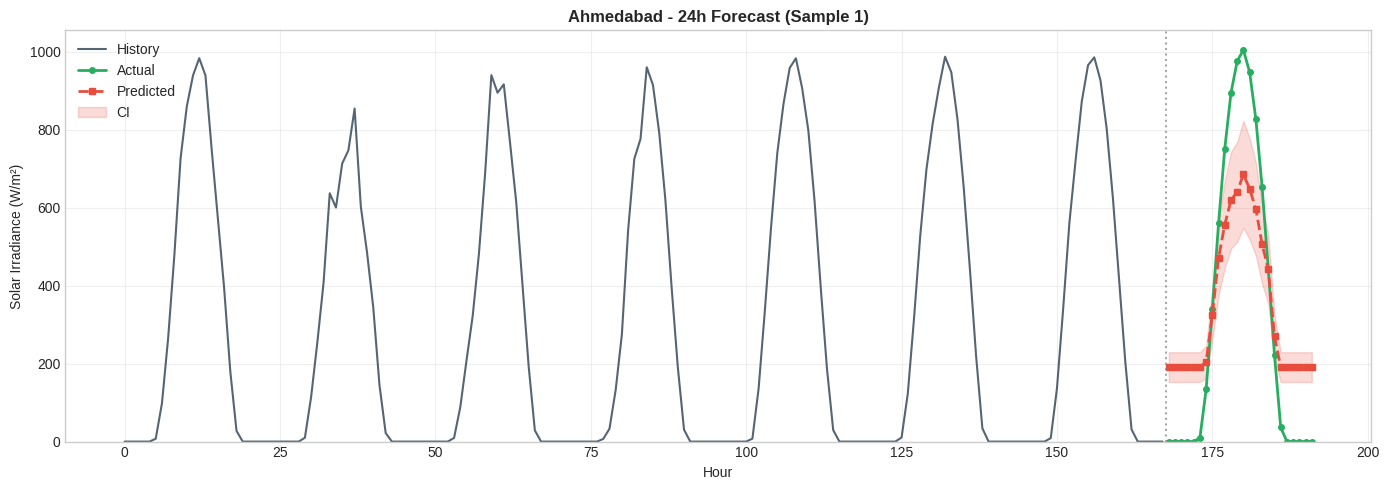

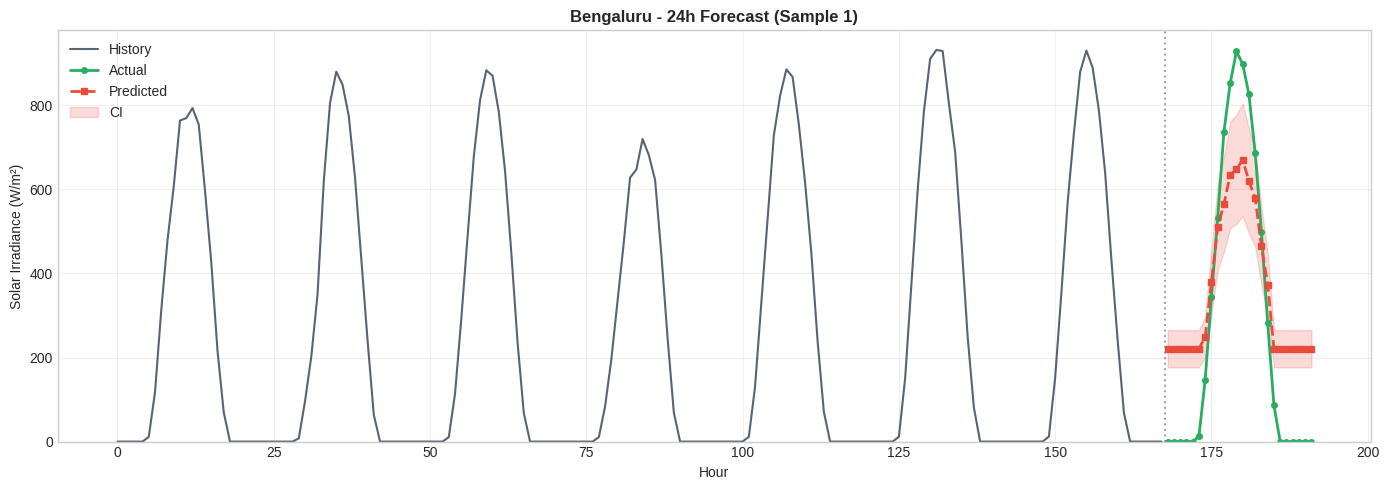

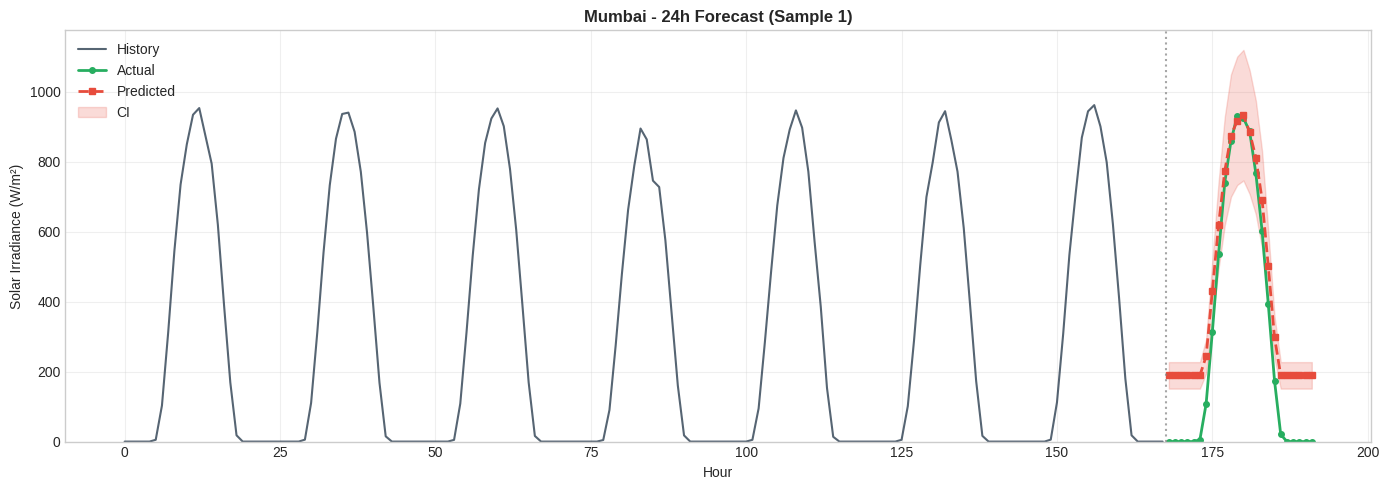

In [17]:
# ============================================================================
# SAMPLE FORECASTS
# ============================================================================

colors = {'Ahmedabad': '#E74C3C', 'Bengaluru': '#3498DB', 'Mumbai': '#27AE60'}

for city, results in all_results.items():
    if len(results) == 0:
        continue
    
    # Find good sample with high irradiance
    for i, r in enumerate(results):
        if np.max(r['target']) > 400:
            fig, ax = plt.subplots(figsize=(14, 5))
            
            ctx_len = len(r['context'])
            pred_len = len(r['pred_median'])
            ctx_idx = np.arange(ctx_len)
            pred_idx = np.arange(ctx_len, ctx_len + pred_len)
            
            ax.plot(ctx_idx, r['context'], color='#2C3E50', lw=1.5, label='History', alpha=0.8)
            ax.plot(pred_idx, r['target'], color='#27AE60', lw=2, label='Actual', marker='o', ms=4)
            ax.plot(pred_idx, r['pred_median'], color='#E74C3C', lw=2, label='Predicted', ls='--', marker='s', ms=4)
            ax.fill_between(pred_idx, r['pred_lower'], r['pred_upper'], color='#E74C3C', alpha=0.2, label='CI')
            ax.axvline(ctx_len - 0.5, color='gray', ls=':', alpha=0.7)
            
            ax.set_xlabel('Hour')
            ax.set_ylabel('Solar Irradiance (W/m²)')
            ax.set_title(f'{city} - 24h Forecast (Sample {i+1})', fontweight='bold')
            ax.legend(loc='upper left')
            ax.grid(True, alpha=0.3)
            ax.set_ylim(bottom=0)
            
            plt.tight_layout()
            plt.show()
            break

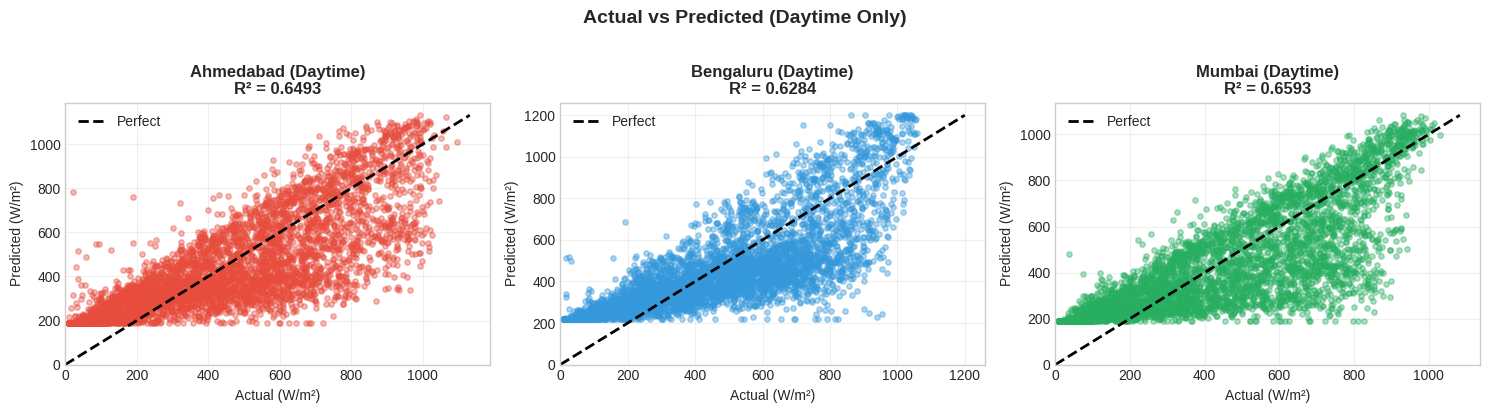

In [18]:
# ============================================================================
# SCATTER PLOTS (DAYTIME)
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (city, results) in zip(axes, all_results.items()):
    if len(results) == 0:
        continue
    
    actual = np.concatenate([r['target'] for r in results])
    pred = np.concatenate([r['pred_median'] for r in results])
    
    # Daytime only
    mask = actual > DAYTIME_THRESHOLD
    actual_day = actual[mask]
    pred_day = pred[mask]
    
    if len(actual_day) > 0:
        r2 = r2_score(actual_day, pred_day)
        ax.scatter(actual_day, pred_day, alpha=0.4, s=15, c=colors.get(city, '#333'))
        
        max_val = max(actual_day.max(), pred_day.max())
        ax.plot([0, max_val], [0, max_val], 'k--', lw=2, label='Perfect')
        
        ax.set_xlabel('Actual (W/m²)')
        ax.set_ylabel('Predicted (W/m²)')
        ax.set_title(f'{city} (Daytime)\nR² = {r2:.4f}', fontweight='bold')
        ax.legend(loc='upper left')
        ax.grid(True, alpha=0.3)
        ax.set_xlim(0, max_val * 1.05)
        ax.set_ylim(0, max_val * 1.05)

plt.suptitle('Actual vs Predicted (Daytime Only)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 11. Save Results

In [19]:
# ============================================================================
# SAVE ALL RESULTS (FIXED JSON SERIALIZATION)
# ============================================================================

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_dir = CONFIG['output_dir'] / f"run_{timestamp}"
output_dir.mkdir(parents=True, exist_ok=True)
graphs_dir = output_dir / "graphs"
graphs_dir.mkdir(exist_ok=True)

print(f"📁 Saving to: {output_dir}")

# 1. Metrics
metrics_df.to_csv(output_dir / "metrics.csv", index=False)
print("✅ metrics.csv")

# 2. Summary - Convert numpy types to Python native types
summary = {
    'timestamp': timestamp,
    'model': CONFIG['model_name'],
    'finetune': {
        'mode': CONFIG['finetune']['mode'],
        'lora_rank': int(CONFIG['finetune']['lora_config']['r']),
        'learning_rate': float(CONFIG['finetune']['learning_rate']),
        'num_steps': int(CONFIG['finetune']['num_steps']),
        'batch_size': int(CONFIG['finetune']['batch_size']),
    },
    'data': {
        'training': 'UK 24 cities (2015-2025)',
        'testing': 'India 3 cities (2023-2025)',
        'train_samples': len(train_inputs),
        'val_samples': len(val_inputs),
    },
    'normalized': CONFIG['normalize'],
    'metrics': {
        'mean_MAE': float(round(metrics_df['MAE (W/m²)'].mean(), 2)),
        'mean_RMSE': float(round(metrics_df['RMSE (W/m²)'].mean(), 2)),
        'mean_R2': float(round(metrics_df['R²'].mean(), 4)),
        'mean_MAPE': float(round(metrics_df['MAPE (%)'].mean(), 1)),
        'mean_MBE': float(round(metrics_df['MBE (W/m²)'].mean(), 2)),
    },
    'per_city': [{k: float(v) if isinstance(v, (np.floating, np.integer)) else v 
                  for k, v in row.items()} 
                 for row in metrics_df.to_dict(orient='records')]
}

with open(output_dir / "summary.json", 'w') as f:
    json.dump(summary, f, indent=2)
print("✅ summary.json")

# 3. Predictions
for city, results in all_results.items():
    if len(results) == 0:
        continue
    preds = []
    for i, r in enumerate(results):
        for h in range(len(r['target'])):
            preds.append({
                'sample': i,
                'hour': h + 1,
                'actual': float(r['target'][h]),
                'predicted': float(r['pred_median'][h]),
                'error': float(r['target'][h] - r['pred_median'][h])
            })
    pd.DataFrame(preds).to_csv(output_dir / f"{city.lower()}_predictions.csv", index=False)
print("✅ *_predictions.csv")

# 4. Save scatter plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (city, results) in zip(axes, all_results.items()):
    if len(results) == 0:
        continue
    actual = np.concatenate([r['target'] for r in results])
    pred = np.concatenate([r['pred_median'] for r in results])
    mask = actual > DAYTIME_THRESHOLD
    actual_day, pred_day = actual[mask], pred[mask]
    if len(actual_day) > 0:
        r2 = r2_score(actual_day, pred_day)
        ax.scatter(actual_day, pred_day, alpha=0.4, s=15, c=colors.get(city, '#333'))
        max_val = max(actual_day.max(), pred_day.max())
        ax.plot([0, max_val], [0, max_val], 'k--', lw=2)
        ax.set_xlabel('Actual')
        ax.set_ylabel('Predicted')
        ax.set_title(f'{city}\nR² = {r2:.4f}')
        ax.set_xlim(0, max_val*1.05)
        ax.set_ylim(0, max_val*1.05)
plt.tight_layout()
fig.savefig(graphs_dir / "scatter_plot.png", dpi=150, bbox_inches='tight')
plt.close()
print("✅ scatter_plot.png")

# Summary
print(f"\n{'='*70}")
print("📊 ALL RESULTS SAVED!")
print(f"{'='*70}")
print(f"📁 {output_dir}")
print(f"\n📈 Final Metrics (Daytime):")
print(f"   • R²: {metrics_df['R²'].mean():.4f}")
print(f"   • MAE: {metrics_df['MAE (W/m²)'].mean():.2f} W/m²")
print(f"   • MAPE: {metrics_df['MAPE (%)'].mean():.1f}%")
print(f"   • MBE: {metrics_df['MBE (W/m²)'].mean():.2f} W/m²")

📁 Saving to: results_v3/run_20260127_073022
✅ metrics.csv
✅ summary.json
✅ *_predictions.csv
✅ scatter_plot.png

📊 ALL RESULTS SAVED!
📁 results_v3/run_20260127_073022

📈 Final Metrics (Daytime):
   • R²: 0.6457
   • MAE: 135.30 W/m²
   • MAPE: 109.3%
   • MBE: -0.01 W/m²
